In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [2]:
class QuadState(TypedDict):
    a : int
    b : int
    c : int

    equation : str
    discriminant : float
    result : str

In [3]:
def generate_equation(state : QuadState):
    equation = f"{state['a']}X²{state['b']}X{state['c']}"
    return {'equation' : equation}

In [4]:
def calculate_discriminant(state : QuadState):
    discriminant = state['b'] ** 2 - (4 * state['a'] * state['c'])
    return {'discriminant' : discriminant}

In [5]:
def real_roots(state : QuadState):
    result = (state['discriminant']) ** 0.5
    root1 = round((-state['b'] + result) / (2 * state['a']),2)
    root2 = round((-state['b'] - result) / (2 * state['a']),2)
    return {'result' : f"root1: {root1}, root2: {root2}"}

In [6]:
def repeated_roots(state : QuadState):
    root = round(-state['b'] / (2 * state['a']), 2)
    return {'result' : f"equal roots: {root}"}

In [7]:
def no_real_roots(state : QuadState):
    return {'result' : f"no real roots"}

In [8]:
def check_condition(state : QuadState) -> Literal['real_roots', 'repeated_roots', 'no_real_roots']:
    if state['discriminant'] > 0:
        return 'real_roots'
    elif state['discriminant'] == 0:
        return 'repeated_roots'
    else:
        return 'no_real_roots'


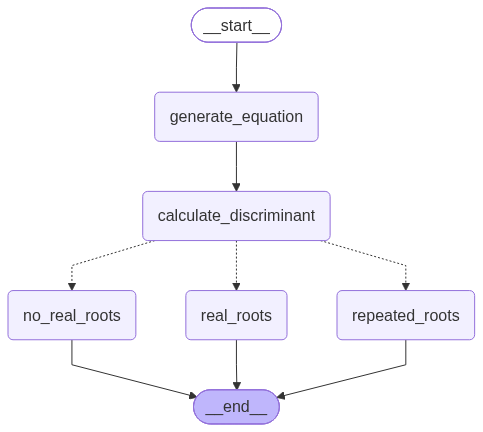

In [9]:
graph = StateGraph(QuadState)

graph.add_node('generate_equation', generate_equation)
graph.add_node('calculate_discriminant', calculate_discriminant)
graph.add_node('real_roots', real_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('no_real_roots', no_real_roots)

graph.add_edge(START, 'generate_equation')
graph.add_edge('generate_equation', 'calculate_discriminant')
graph.add_conditional_edges('calculate_discriminant', check_condition)

graph.add_edge('real_roots', END)
graph.add_edge('repeated_roots', END)
graph.add_edge('no_real_roots', END)

workflow = graph.compile()
workflow

In [10]:
initial_state = {
    'a' : 4,
    'b' : -5,
    'c' : -4
}
final_state = workflow.invoke(initial_state)
final_state

{'a': 4,
 'b': -5,
 'c': -4,
 'equation': '4X²-5X-4',
 'discriminant': 89,
 'result': 'root1: 1.8, root2: -0.55'}

In [11]:
print(final_state['result'])

root1: 1.8, root2: -0.55
